# P01 First Practice - AliceVision Step-by-Step Photogrammetry

Notebook này triển khai pipeline 3D reconstruction cho bộ ảnh `P01_first-practice` bằng các node CLI của AliceVision/Meshroom. Mục tiêu là chạy từng giai đoạn riêng, kiểm tra output trung gian, và trực quan hóa kết quả để dễ đánh giá chất lượng trước khi chuyển sang bước tiếp theo.

Pipeline chính:

1. Kiểm tra dataset ảnh đầu vào.
2. `CameraInit` tạo SfMData ban đầu.
3. `FeatureExtraction` trích xuất đặc trưng ảnh.
4. `ImageMatching` chọn các cặp ảnh có khả năng trùng vùng nhìn.
5. `FeatureMatching` tính match hình học giữa các cặp ảnh.
6. `IncrementalSfM` dựng camera poses và sparse point cloud.
7. `PrepareDenseScene` chuẩn bị ảnh đã hiệu chỉnh cho dense reconstruction.
8. `DepthMapEstimation` tạo depth maps bằng GPU CUDA.
9. `DepthMapFiltering` lọc depth maps.
10. `Meshing` dựng mesh thô.
11. `MeshFiltering` lọc mesh.
12. `Texturing` tạo textured mesh cuối cùng.

Các cell command có thể chạy từng bước. Notebook này được tạo với output rỗng; chưa có cell nào được execute.

## 0. Cấu hình đường dẫn và tham số chung

Cell dưới đây gom toàn bộ đường dẫn, biến môi trường và tham số quan trọng. Nếu muốn chạy thử nhẹ hơn, giảm `DESCRIBER_PRESET`, tăng `DEPTH_DOWNSCALE`, hoặc giảm `TEXTURE_SIDE` trước khi chạy pipeline.

`RUN_COMMANDS = True` nghĩa là các cell command sẽ chạy thật khi bạn execute. Đổi thành `False` nếu chỉ muốn in lệnh để kiểm tra.

In [1]:
from pathlib import Path
import os
import sys
import json
import shlex
import subprocess
import time
import math
from collections import Counter, defaultdict, deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from PIL import Image, ImageOps

PROJECT_DIR = Path("/home/dacekey/dariusuav/alicevision/project/P01_first-practice")
MESHROOM_DIR = Path("/home/dacekey/dariusuav/alicevision/Meshroom-2023.3.0")
ALICEVISION_DIR = MESHROOM_DIR / "aliceVision"
AV_BIN = ALICEVISION_DIR / "bin"
AV_SHARE = ALICEVISION_DIR / "share" / "aliceVision"

IMAGES_DIR = PROJECT_DIR / "images"
OUTPUT_DIR = PROJECT_DIR / "output"
CACHE_DIR = OUTPUT_DIR / "cache"
REPORTS_DIR = OUTPUT_DIR / "reports"

STAGE_DIRS = {
    "cameraInit": CACHE_DIR / "01_cameraInit",
    "features": CACHE_DIR / "02_features",
    "imageMatching": CACHE_DIR / "03_imageMatching",
    "matches": CACHE_DIR / "04_matches",
    "sfm": CACHE_DIR / "05_sfm",
    "prepareDenseScene": CACHE_DIR / "06_prepareDenseScene",
    "depthMap": CACHE_DIR / "07_depthMap",
    "depthMapFilter": CACHE_DIR / "08_depthMapFilter",
    "meshing": CACHE_DIR / "09_meshing",
    "meshFiltering": CACHE_DIR / "10_meshFiltering",
    "texturing": OUTPUT_DIR / "texturing",
}

for folder in [OUTPUT_DIR, CACHE_DIR, REPORTS_DIR, *STAGE_DIRS.values()]:
    folder.mkdir(parents=True, exist_ok=True)

CAMERA_DB = AV_SHARE / "cameraSensors.db"
VOC_TREE = AV_SHARE / "vlfeat_K80L3.SIFT.tree"

CAMERA_INIT_SFM = STAGE_DIRS["cameraInit"] / "cameraInit.sfm"
IMAGE_PAIRS = STAGE_DIRS["imageMatching"] / "imagePairs.txt"
SFM = STAGE_DIRS["sfm"] / "sfm.sfm"
CAMERAS_SFM = STAGE_DIRS["sfm"] / "cameras.sfm"
DENSE_SFM = STAGE_DIRS["meshing"] / "densePointCloud.abc"
RAW_MESH = STAGE_DIRS["meshing"] / "mesh.obj"
FILTERED_MESH = STAGE_DIRS["meshFiltering"] / "mesh_filtered.obj"
TEXTURED_DIR = STAGE_DIRS["texturing"]

DESCRIBER_TYPES = "sift"
DESCRIBER_PRESET = "normal"
IMAGE_MATCHING_METHOD = "VocabularyTree"
NB_IMAGE_MATCHES = 50
PREPARE_DENSE_IMAGE_TYPE = "png"
DEPTH_DOWNSCALE = 2
TEXTURE_SIDE = 8192
MAX_CORES = os.cpu_count() or 4
RUN_COMMANDS = True

AV_ENV = os.environ.copy()
AV_ENV["ALICEVISION_ROOT"] = str(ALICEVISION_DIR)
lib_paths = [str(MESHROOM_DIR / "lib"), str(ALICEVISION_DIR / "lib")]
if AV_ENV.get("LD_LIBRARY_PATH"):
    lib_paths.append(AV_ENV["LD_LIBRARY_PATH"])
AV_ENV["LD_LIBRARY_PATH"] = ":".join(lib_paths)
AV_ENV["PATH"] = f"{AV_BIN}:{MESHROOM_DIR}:{AV_ENV.get('PATH', '')}"
AV_ENV.setdefault("QT_QPA_PLATFORM", "offscreen")
AV_ENV["OPENCV_IO_ENABLE_OPENEXR"] = "1"


def av_tool(name: str) -> str:
    path = AV_BIN / f"aliceVision_{name}"
    if not path.exists():
        raise FileNotFoundError(path)
    return str(path)

print(f"Project: {PROJECT_DIR}")
print(f"Images:  {IMAGES_DIR}")
print(f"Output:  {OUTPUT_DIR}")
print(f"AliceVision bin: {AV_BIN}")
print(f"RUN_COMMANDS = {RUN_COMMANDS}")


Project: /home/dacekey/dariusuav/alicevision/project/P01_first-practice
Images:  /home/dacekey/dariusuav/alicevision/project/P01_first-practice/images
Output:  /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output
AliceVision bin: /home/dacekey/dariusuav/alicevision/Meshroom-2023.3.0/aliceVision/bin
RUN_COMMANDS = True


## 1. Helper chạy lệnh và lưu log

Mỗi node AliceVision có thể chạy lâu. Helper `run_command` sẽ:

- in command đầy đủ để kiểm tra;
- ghi toàn bộ log vào `output/reports/*.log`;
- chỉ hiển thị phần cuối log trong notebook để output không quá dài;
- raise error nếu command trả về exit code khác `0`.

In [2]:
def run_command(cmd, step_name: str, cwd: Path = PROJECT_DIR, env: dict = AV_ENV):
    cmd = [str(part) for part in cmd]
    log_path = REPORTS_DIR / f"{step_name}.log"

    print("$", shlex.join(cmd))
    print(f"Log file: {log_path}")

    if not RUN_COMMANDS:
        print("RUN_COMMANDS=False, command was not executed.")
        return None

    start = time.time()
    tail = deque(maxlen=40)

    with log_path.open("w", encoding="utf-8", errors="replace") as log_file:
        process = subprocess.Popen(
            cmd,
            cwd=str(cwd),
            env=env,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            encoding="utf-8",
            errors="replace",
            bufsize=1,
        )
        for line in process.stdout:
            log_file.write(line)
            tail.append(line.rstrip())
        return_code = process.wait()

    elapsed = time.time() - start
    print(f"Exit code: {return_code} | elapsed: {elapsed / 60:.1f} min")
    if tail:
        print("\nLast log lines:")
        print("\n".join(tail))

    if return_code != 0:
        raise subprocess.CalledProcessError(return_code, cmd)

    return log_path


def file_size_mb(path: Path) -> float:
    return path.stat().st_size / (1024 * 1024)


def list_files(folder: Path, patterns=("*",), recursive=False):
    files = []
    globber = folder.rglob if recursive else folder.glob
    for pattern in patterns:
        files.extend(p for p in globber(pattern) if p.is_file())
    return sorted(set(files))


def show_file_inventory(folder: Path, patterns=("*",), recursive=False, max_rows=30):
    files = list_files(folder, patterns=patterns, recursive=recursive)
    rows = [
        {
            "name": path.name,
            "relative_path": str(path.relative_to(PROJECT_DIR)) if path.is_relative_to(PROJECT_DIR) else str(path),
            "suffix": path.suffix.lower(),
            "size_mb": file_size_mb(path),
        }
        for path in files
    ]
    df = pd.DataFrame(rows)
    print(f"{folder}: {len(files)} files")
    if not df.empty:
        display(df.head(max_rows))
        summary = df.groupby("suffix", dropna=False)["size_mb"].agg(["count", "sum", "mean"]).reset_index()
        display(summary)
    return df


def load_sfm_json(path: Path):
    if not path.exists():
        raise FileNotFoundError(path)
    with path.open("r", encoding="utf-8") as f:
        return json.load(f)


def value_as_vector(value, length=3):
    if value is None:
        return None
    if isinstance(value, str):
        raw = value.replace(",", " ").split()
    elif isinstance(value, dict):
        raw = [value.get(k) for k in ("x", "y", "z")]
    else:
        raw = value
    try:
        arr = np.asarray(raw, dtype=float).reshape(-1)
    except Exception:
        return None
    if arr.size < length:
        return None
    return arr[:length]

## 2. Visualization helper

Các hàm bên dưới phục vụ quan sát dataset, SfM, depth map, và mesh. Chúng được viết theo hướng tolerant: nếu một format không đọc được trực tiếp, notebook vẫn hiển thị inventory/file statistics thay vì dừng toàn bộ phân tích.

In [3]:
def get_image_files(folder: Path = IMAGES_DIR):
    exts = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"}
    return sorted(p for p in folder.iterdir() if p.is_file() and p.suffix.lower() in exts)


def display_image_grid(paths, cols=4, figsize=(14, 8), title=None, max_images=12):
    paths = list(paths)[:max_images]
    if not paths:
        print("No images to display.")
        return
    rows = math.ceil(len(paths) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = np.asarray(axes).reshape(-1)
    for ax, path in zip(axes, paths):
        with Image.open(path) as img:
            img = ImageOps.exif_transpose(img).convert("RGB")
            ax.imshow(img)
        ax.set_title(path.name, fontsize=9)
        ax.axis("off")
    for ax in axes[len(paths):]:
        ax.axis("off")
    if title:
        fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


def summarize_sfm(path: Path):
    sfm = load_sfm_json(path)
    counts = {
        "views": len(sfm.get("views", [])),
        "intrinsics": len(sfm.get("intrinsics", [])),
        "poses": len(sfm.get("poses", [])),
        "landmarks": len(sfm.get("structure", [])),
    }
    display(pd.DataFrame([counts]))

    views = []
    for view in sfm.get("views", [])[:20]:
        views.append({
            "viewId": view.get("viewId"),
            "poseId": view.get("poseId"),
            "intrinsicId": view.get("intrinsicId"),
            "path": Path(view.get("path", "")).name,
            "width": view.get("width"),
            "height": view.get("height"),
        })
    if views:
        display(pd.DataFrame(views))
    return sfm


def extract_camera_centers(sfm: dict):
    centers = []
    for pose_item in sfm.get("poses", []):
        transform = pose_item.get("pose", {}).get("transform", {})
        center = value_as_vector(transform.get("center"))
        if center is not None:
            centers.append(center)
    return np.asarray(centers, dtype=float) if centers else np.empty((0, 3))


def extract_landmarks(sfm: dict, max_points=50000):
    points = []
    for landmark in sfm.get("structure", []):
        point = value_as_vector(landmark.get("X") or landmark.get("x"))
        if point is not None:
            points.append(point)
    if not points:
        return np.empty((0, 3))
    points = np.asarray(points, dtype=float)
    if len(points) > max_points:
        rng = np.random.default_rng(42)
        idx = rng.choice(len(points), size=max_points, replace=False)
        points = points[idx]
    return points


def plot_sfm_3d(path: Path, title="SfM overview"):
    if not path.exists():
        print(f"Missing SfM file: {path}")
        return
    sfm = load_sfm_json(path)
    cameras = extract_camera_centers(sfm)
    points = extract_landmarks(sfm)

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")
    if len(points):
        ax.scatter(points[:, 0], points[:, 1], points[:, 2], s=0.5, alpha=0.35, c="steelblue", label="landmarks")
    if len(cameras):
        ax.scatter(cameras[:, 0], cameras[:, 1], cameras[:, 2], s=28, c="crimson", label="cameras")
    ax.set_title(title)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    ax.legend(loc="best")
    plt.tight_layout()
    plt.show()


def parse_image_pairs(path: Path):
    pairs = []
    if not path.exists():
        print(f"Missing pair list: {path}")
        return pairs
    for line in path.read_text(encoding="utf-8", errors="replace").splitlines():
        line = line.split("#", 1)[0].strip()
        if not line:
            continue
        numeric = [token for token in line.replace(",", " ").split() if token.lstrip("-").isdigit()]
        if len(numeric) == 2:
            pairs.append((numeric[0], numeric[1]))
        elif len(numeric) > 2:
            src = numeric[0]
            pairs.extend((src, dst) for dst in numeric[1:])
    return pairs


def visualize_image_pairs(path: Path):
    pairs = parse_image_pairs(path)
    print(f"Pairs: {len(pairs)}")
    if not pairs:
        return

    degree = Counter()
    for a, b in pairs:
        degree[a] += 1
        degree[b] += 1
    degree_df = pd.DataFrame({"viewId": list(degree.keys()), "degree": list(degree.values())}).sort_values("degree", ascending=False)
    display(degree_df.head(20))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].hist(degree_df["degree"], bins=30, color="slateblue", alpha=0.85)
    axes[0].set_title("Image-pair degree distribution")
    axes[0].set_xlabel("number of selected neighbors")
    axes[0].set_ylabel("image count")

    ids = sorted(degree.keys(), key=lambda x: int(x) if x.lstrip("-").isdigit() else x)
    id_to_idx = {view_id: i for i, view_id in enumerate(ids)}
    matrix = np.zeros((len(ids), len(ids)), dtype=np.uint8)
    for a, b in pairs:
        ia, ib = id_to_idx[a], id_to_idx[b]
        matrix[ia, ib] = 1
        matrix[ib, ia] = 1
    axes[1].imshow(matrix, cmap="Greys", interpolation="nearest")
    axes[1].set_title("Pair adjacency matrix")
    axes[1].set_xlabel("view index")
    axes[1].set_ylabel("view index")
    plt.tight_layout()
    plt.show()


def read_scalar_image(path: Path):
    suffix = path.suffix.lower()
    if suffix == ".exr":
        try:
            import imageio.v3 as iio
            image = iio.imread(str(path))
            if image is not None:
                return image.astype(float)
        except Exception:
            pass
        try:
            import os, cv2
            os.environ["OPENCV_IO_ENABLE_OPENEXR"] = "1"
            image = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
            if image is not None:
                return image.astype(float)
        except Exception as exc:
            print(f"Cannot read EXR: {path.name} ({exc})")
            return None
        return None
    try:
        with Image.open(path) as img:
            arr = np.asarray(img)
        return arr.astype(float)
    except Exception as exc:
        print(f"Cannot read image: {path.name} ({exc})")
        return None


def visualize_scalar_maps(folder: Path, title: str, max_images=6):
    patterns = ("*.exr", "*.png", "*.tif", "*.tiff", "*.jpg")
    files = list_files(folder, patterns=patterns, recursive=True)
    print(f"{title}: {len(files)} map/image files")
    if not files:
        return
    display(pd.DataFrame([{"name": f.name, "suffix": f.suffix, "size_mb": file_size_mb(f)} for f in files[:20]]))

    samples = files[:max_images]
    cols = min(3, len(samples))
    rows = math.ceil(len(samples) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
    axes = np.asarray(axes).reshape(-1)
    for ax, path in zip(axes, samples):
        arr = read_scalar_image(path)
        if arr is None:
            ax.text(0.5, 0.5, "unreadable", ha="center", va="center")
        elif arr.ndim == 3:
            if "normal" in path.name.lower():
                rgb = np.clip((arr + 1.0) / 2.0, 0.0, 1.0)
                ax.imshow(rgb)
            else:
                finite = arr[np.isfinite(arr)]
                if finite.size:
                    vmin, vmax = np.nanpercentile(finite, [2, 98])
                    rgb = np.clip((arr - vmin) / (vmax - vmin + 1e-8), 0.0, 1.0)
                    ax.imshow(rgb)
                else:
                    ax.imshow(np.clip(arr / 255.0, 0.0, 1.0))
        else:
            if "depth" in path.name.lower():
                arr_plot = arr.copy()
                arr_plot[arr_plot <= 0] = np.nan
                finite = arr_plot[np.isfinite(arr_plot)]
            else:
                arr_plot = arr
                finite = arr[np.isfinite(arr)]
            if finite.size:
                vmin, vmax = np.nanpercentile(finite, [2, 98])
            else:
                vmin, vmax = None, None
            ax.imshow(arr_plot, cmap="viridis", vmin=vmin, vmax=vmax)
        ax.set_title(path.name, fontsize=8)
        ax.axis("off")
    for ax in axes[len(samples):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


def obj_stats(path: Path):
    stats = {"path": str(path), "exists": path.exists(), "vertices": 0, "faces": 0, "size_mb": None}
    if not path.exists():
        return stats
    stats["size_mb"] = file_size_mb(path)
    mins = np.array([np.inf, np.inf, np.inf])
    maxs = np.array([-np.inf, -np.inf, -np.inf])
    with path.open("r", encoding="utf-8", errors="replace") as f:
        for line in f:
            if line.startswith("v "):
                stats["vertices"] += 1
                parts = line.split()
                if len(parts) >= 4:
                    xyz = np.asarray(parts[1:4], dtype=float)
                    mins = np.minimum(mins, xyz)
                    maxs = np.maximum(maxs, xyz)
            elif line.startswith("f "):
                stats["faces"] += 1
    if np.isfinite(mins).all():
        stats.update({"bbox_x": maxs[0] - mins[0], "bbox_y": maxs[1] - mins[1], "bbox_z": maxs[2] - mins[2]})
    return stats


def preview_obj(path: Path, title="Mesh preview", max_vertices=50000):
    if not path.exists():
        print(f"Missing mesh: {path}")
        return
    try:
        import trimesh
        import plotly.graph_objects as go
        mesh = trimesh.load(str(path), force="mesh", process=False)
        vertices = np.asarray(mesh.vertices)
        faces = np.asarray(mesh.faces)
        if len(faces) > max_vertices:
            rng = np.random.default_rng(42)
            faces = faces[rng.choice(len(faces), size=max_vertices, replace=False)]
        fig = go.Figure(data=[go.Mesh3d(
            x=vertices[:, 0], y=vertices[:, 1], z=vertices[:, 2],
            i=faces[:, 0], j=faces[:, 1], k=faces[:, 2],
            opacity=0.85,
            intensity=vertices[:, 2],
            colorscale="Viridis",
        )])
        fig.update_layout(title=title, scene_aspectmode="data", height=700)
        fig.show()
        return
    except Exception as exc:
        print(f"Interactive mesh preview unavailable, falling back to vertex scatter. Reason: {exc}")

    vertices = []
    with path.open("r", encoding="utf-8", errors="replace") as f:
        for line in f:
            if line.startswith("v "):
                parts = line.split()
                if len(parts) >= 4:
                    vertices.append([float(parts[1]), float(parts[2]), float(parts[3])])
                    if len(vertices) >= max_vertices:
                        break
    vertices = np.asarray(vertices)
    if vertices.size == 0:
        print("No vertices found.")
        return
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(vertices[:, 0], vertices[:, 1], vertices[:, 2], s=0.4, alpha=0.35)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


## 3. Kiểm tra dataset đầu vào

Mục tiêu của bước này là xác nhận số lượng ảnh, dung lượng, kích thước ảnh và xem nhanh một số frame đại diện. Nếu ảnh bị xoay sai EXIF, quá tối, quá mờ, hoặc thiếu overlap, lỗi sẽ thường xuất hiện rõ ngay tại đây.

Image count: 176


,name,width,height,megapixels,size_mb
0,MAX_0002.JPG,5472,3648,19.961856,15.142491
1,MAX_0003.JPG,5472,3648,19.961856,14.578064
2,MAX_0004.JPG,5472,3648,19.961856,14.186060
3,MAX_0005.JPG,5472,3648,19.961856,13.994684
4,MAX_0006.JPG,5472,3648,19.961856,13.720876


,width,height,megapixels,size_mb
count,176.0,176.0,1.760000e+02,176.000000
mean,5472.0,3648.0,1.996186e+01,13.836547
std,0.0,0.0,7.125700e-14,0.871143
min,5472.0,3648.0,1.996186e+01,11.446754
25%,5472.0,3648.0,1.996186e+01,13.266507
50%,5472.0,3648.0,1.996186e+01,13.682819
75%,5472.0,3648.0,1.996186e+01,14.192616
max,5472.0,3648.0,1.996186e+01,16.431582


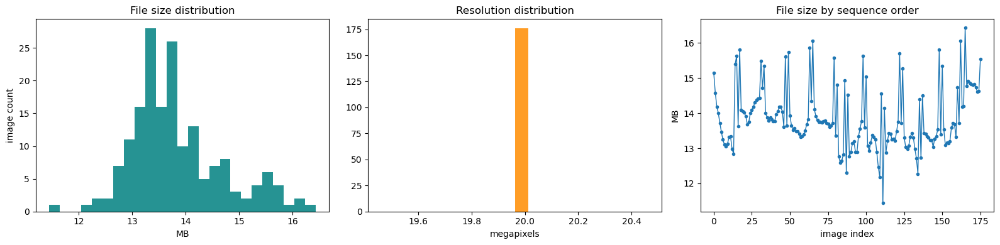

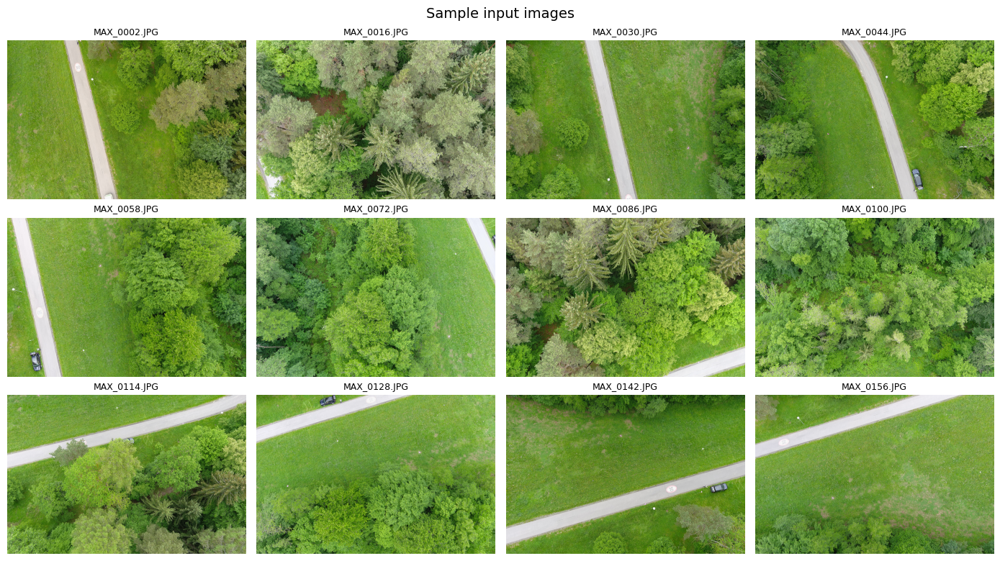

In [7]:
image_paths = get_image_files(IMAGES_DIR)
print(f"Image count: {len(image_paths)}")

rows = []
for path in image_paths:
    with Image.open(path) as img:
        rows.append({
            "name": path.name,
            "width": img.width,
            "height": img.height,
            "megapixels": img.width * img.height / 1e6,
            "size_mb": file_size_mb(path),
        })
image_df = pd.DataFrame(rows)
display(image_df.head())
numeric_summary = image_df.select_dtypes(include="number")
display(numeric_summary.describe())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(image_df["size_mb"], bins=25, color="teal", alpha=0.85)
axes[0].set_title("File size distribution")
axes[0].set_xlabel("MB")
axes[0].set_ylabel("image count")

axes[1].hist(image_df["megapixels"], bins=20, color="darkorange", alpha=0.85)
axes[1].set_title("Resolution distribution")
axes[1].set_xlabel("megapixels")

axes[2].plot(image_df.index, image_df["size_mb"], marker=".", linewidth=1)
axes[2].set_title("File size by sequence order")
axes[2].set_xlabel("image index")
axes[2].set_ylabel("MB")
plt.tight_layout()
plt.show()

display_image_grid(image_paths[::max(1, len(image_paths) // 12)], cols=4, title="Sample input images")

## 4. CameraInit

`CameraInit` đọc EXIF, nhận diện sensor/lens trong `cameraSensors.db`, và tạo file `cameraInit.sfm`. File này là nền tảng cho toàn bộ pipeline: mỗi ảnh trở thành một `view`, và các nhóm camera dùng chung intrinsic sẽ được khai báo ở `intrinsics`.

Output cần kiểm tra:

- số `views` phải gần bằng số ảnh đầu vào;
- `intrinsics` không được rỗng;
- đường dẫn ảnh trong `views` phải đúng.

In [8]:
camera_init_cmd = [
    av_tool("cameraInit"),
    "--imageFolder", IMAGES_DIR,
    "--sensorDatabase", CAMERA_DB,
    "--output", CAMERA_INIT_SFM,
    "--groupCameraFallback", "folder",
    "--viewIdMethod", "metadata",
    "--verboseLevel", "info",
]
run_command(camera_init_cmd, "01_cameraInit")

$ /home/dacekey/dariusuav/alicevision/Meshroom-2023.3.0/aliceVision/bin/aliceVision_cameraInit --imageFolder /home/dacekey/dariusuav/alicevision/project/P01_first-practice/images --sensorDatabase /home/dacekey/dariusuav/alicevision/Meshroom-2023.3.0/aliceVision/share/aliceVision/cameraSensors.db --output /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/01_cameraInit/cameraInit.sfm --groupCameraFallback folder --viewIdMethod metadata --verboseLevel info
Log file: /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/reports/01_cameraInit.log
Exit code: 0 | elapsed: 0.0 min

Last log lines:
 * colorProfileDatabase = "" (default)
 * defaultCameraModel = "" (default)
 * defaultFieldOfView = -1 (default)
 * defaultFocalLength = -1 (default)
 * defaultFocalRatio = 1 (default)
 * defaultOffsetX = 0 (default)
 * defaultOffsetY = 0 (default)
 * errorOnMissingColorProfile = 1 (default)
 * groupCameraFallback =  Unknown Type "20EGroupCameraFallback"
 * i

PosixPath('/home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/reports/01_cameraInit.log')

In [9]:
sfm_camera_init = summarize_sfm(CAMERA_INIT_SFM)

intrinsics = sfm_camera_init.get("intrinsics", [])
if intrinsics:
    intrinsic_rows = []
    for item in intrinsics:
        intrinsic_rows.append({
            "intrinsicId": item.get("intrinsicId"),
            "sensorWidth": item.get("sensorWidth"),
            "width": item.get("width"),
            "height": item.get("height"),
            "serialNumber": item.get("serialNumber"),
            "type": item.get("type"),
        })
    display(pd.DataFrame(intrinsic_rows))

,views,intrinsics,poses,landmarks
0,176,1,0,0


,viewId,poseId,intrinsicId,path,width,height
0,11855485,11855485,3674969038,MAX_0124.JPG,5472,3648
1,38932963,38932963,3674969038,MAX_0100.JPG,5472,3648
2,40390399,40390399,3674969038,MAX_0174.JPG,5472,3648
3,57733051,57733051,3674969038,MAX_0024.JPG,5472,3648
4,58599558,58599558,3674969038,MAX_0107.JPG,5472,3648
5,91331686,91331686,3674969038,MAX_0069.JPG,5472,3648
6,95700226,95700226,3674969038,MAX_0102.JPG,5472,3648
7,121530303,121530303,3674969038,MAX_0061.JPG,5472,3648
8,142491675,142491675,3674969038,MAX_0161.JPG,5472,3648
9,144974563,144974563,3674969038,MAX_0127.JPG,5472,3648


,intrinsicId,sensorWidth,width,height,serialNumber,type
0,3674969038,13.12137931034483,5472,3648,/home/dacekey/dariusuav/alicevision/project/P0...,radial3


## 5. FeatureExtraction

`FeatureExtraction` trích xuất keypoints/descriptors từ từng ảnh. Với bộ ảnh 176 ảnh độ phân giải cao, `DESCRIBER_PRESET = "normal"` là điểm cân bằng hợp lý. Nếu ảnh ít texture hoặc match yếu, có thể đổi sang `high`; nếu chỉ test nhanh, dùng `medium`.

Output cần kiểm tra:

- số file `.feat` và `.desc` phải tương ứng với số ảnh;
- dung lượng feature không được bất thường bằng 0;
- nếu `.feat` đọc được dạng text, notebook sẽ overlay keypoints lên ảnh mẫu.

In [10]:
feature_extraction_cmd = [
    av_tool("featureExtraction"),
    "--input", CAMERA_INIT_SFM,
    "--output", STAGE_DIRS["features"],
    "--describerTypes", DESCRIBER_TYPES,
    "--describerPreset", DESCRIBER_PRESET,
    "--maxCoresAvailable", MAX_CORES,
    "--verboseLevel", "info",
]
run_command(feature_extraction_cmd, "02_featureExtraction")

$ /home/dacekey/dariusuav/alicevision/Meshroom-2023.3.0/aliceVision/bin/aliceVision_featureExtraction --input /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/01_cameraInit/cameraInit.sfm --output /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/02_features --describerTypes sift --describerPreset normal --maxCoresAvailable 12 --verboseLevel info
Log file: /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/reports/02_featureExtraction.log
Exit code: 0 | elapsed: 2.3 min

Last log lines:
[14:15:16.051280][info]       25291 sift features extracted from view '/home/dacekey/dariusuav/alicevision/project/P01_first-practice/images/MAX_0160.JPG'
[14:15:16.586963][info] Extracting sift features from view '/home/dacekey/dariusuav/alicevision/project/P01_first-practice/images/MAX_0123.JPG' [gpu]
[14:15:16.836079][info]       24733 sift features extracted from view '/home/dacekey/dariusuav/alicevision/project/P01_first-practi

PosixPath('/home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/reports/02_featureExtraction.log')

/home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/02_features: 352 files


,name,relative_path,suffix,size_mb
0,1004768684.sift.desc,output/cache/02_features/1004768684.sift.desc,.desc,3.006355
1,1004768684.sift.feat,output/cache/02_features/1004768684.sift.feat,.feat,0.761000
2,1039115835.sift.desc,output/cache/02_features/1039115835.sift.desc,.desc,3.043343
3,1039115835.sift.feat,output/cache/02_features/1039115835.sift.feat,.feat,0.770072
4,1053141325.sift.desc,output/cache/02_features/1053141325.sift.desc,.desc,3.055672
5,1053141325.sift.feat,output/cache/02_features/1053141325.sift.feat,.feat,0.772688
6,1054854377.sift.desc,output/cache/02_features/1054854377.sift.desc,.desc,3.069221
7,1054854377.sift.feat,output/cache/02_features/1054854377.sift.feat,.feat,0.776481
8,1056044198.sift.desc,output/cache/02_features/1056044198.sift.desc,.desc,3.056648
9,1056044198.sift.feat,output/cache/02_features/1056044198.sift.feat,.feat,0.773272


,suffix,count,sum,mean
0,.desc,176,537.607422,3.054588
1,.feat,176,136.007125,0.772768


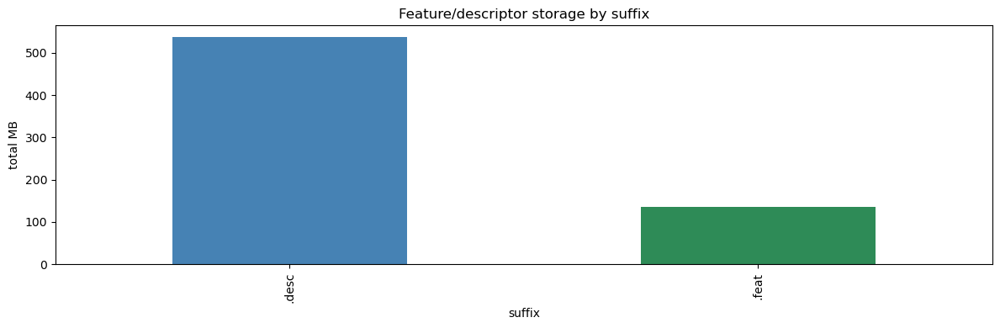

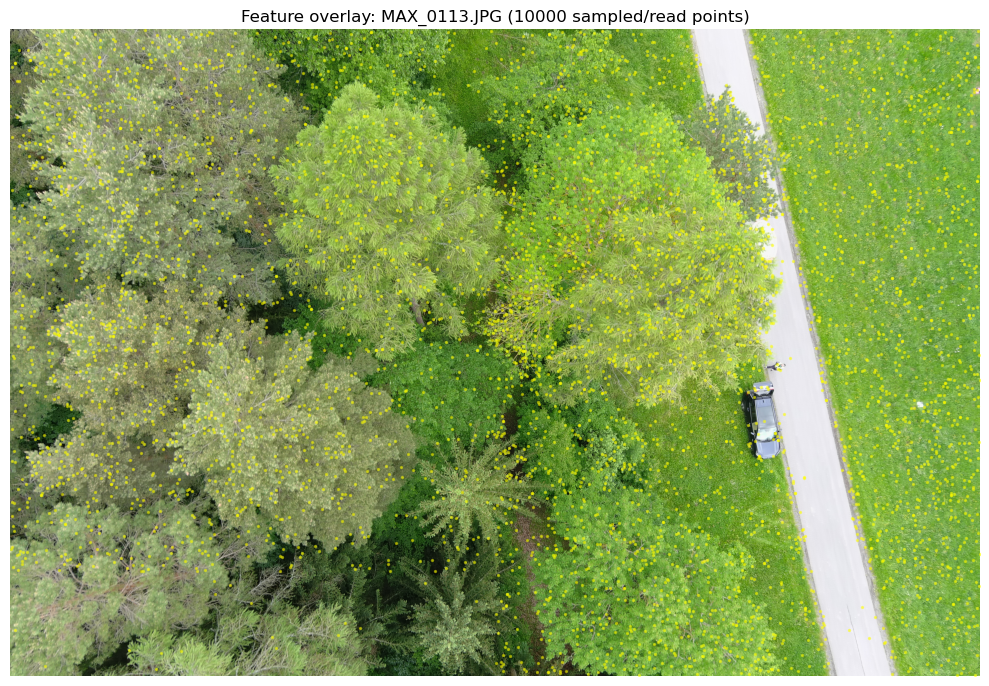

In [11]:
features_df = show_file_inventory(
    STAGE_DIRS["features"],
    patterns=("*.feat", "*.desc"),
    recursive=False,
)

if not features_df.empty:
    fig, ax = plt.subplots(figsize=(12, 4))
    features_df.groupby("suffix")["size_mb"].sum().plot(kind="bar", ax=ax, color=["steelblue", "seagreen"])
    ax.set_title("Feature/descriptor storage by suffix")
    ax.set_ylabel("total MB")
    plt.tight_layout()
    plt.show()


def try_read_feature_points(path: Path, max_points=10000):
    try:
        arr = np.loadtxt(path, usecols=(0, 1), max_rows=max_points)
        arr = np.asarray(arr, dtype=float)
        if arr.ndim == 1 and arr.size >= 2:
            arr = arr.reshape(1, -1)
        if arr.ndim == 2 and arr.shape[1] >= 2:
            return arr[:, :2]
    except Exception:
        return None
    return None


def build_view_path_map(sfm: dict):
    mapping = {}
    for view in sfm.get("views", []):
        view_id = str(view.get("viewId"))
        path = Path(view.get("path", ""))
        if not path.exists():
            path = IMAGES_DIR / path.name
        mapping[view_id] = path
    return mapping

view_paths = build_view_path_map(sfm_camera_init)
feat_files = list_files(STAGE_DIRS["features"], patterns=("*.feat",))
plotted = False
for feat_path in feat_files[:20]:
    points = try_read_feature_points(feat_path)
    if points is None:
        continue
    view_key = feat_path.stem.split(".")[0]
    image_path = view_paths.get(view_key)
    if image_path is None or not image_path.exists():
        continue
    with Image.open(image_path) as img:
        img = ImageOps.exif_transpose(img).convert("RGB")
    sample = points[::max(1, len(points) // 5000)]
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.imshow(img)
    ax.scatter(sample[:, 0], sample[:, 1], s=2, c="yellow", alpha=0.45)
    ax.set_title(f"Feature overlay: {image_path.name} ({len(points)} sampled/read points)")
    ax.axis("off")
    plt.tight_layout()
    plt.show()
    plotted = True
    break

if not plotted:
    print("Feature files were not directly readable as text. Inventory above is still useful for checking completeness and size.")

## 6. ImageMatching

`ImageMatching` chọn trước các cặp ảnh có khả năng nhìn cùng vùng cảnh. Với dataset 176 ảnh, dùng vocabulary tree giúp giảm số cặp phải match chi tiết so với exhaustive matching, nhưng vẫn giữ đủ neighbor cho object reconstruction.

Output cần kiểm tra:

- tổng số pair không quá thấp;
- degree distribution không có nhiều ảnh degree bằng 0;
- adjacency matrix có cấu trúc liên thông hợp lý.

In [12]:
image_matching_cmd = [
    av_tool("imageMatching"),
    "--input", CAMERA_INIT_SFM,
    "--featuresFolders", STAGE_DIRS["features"],
    "--output", IMAGE_PAIRS,
    "--method", IMAGE_MATCHING_METHOD,
    "--tree", VOC_TREE,
    "--minNbImages", 1,
    "--nbMatches", NB_IMAGE_MATCHES,
    "--verboseLevel", "info",
]
run_command(image_matching_cmd, "03_imageMatching")

$ /home/dacekey/dariusuav/alicevision/Meshroom-2023.3.0/aliceVision/bin/aliceVision_imageMatching --input /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/01_cameraInit/cameraInit.sfm --featuresFolders /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/02_features --output /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/03_imageMatching/imagePairs.txt --method VocabularyTree --tree /home/dacekey/dariusuav/alicevision/Meshroom-2023.3.0/aliceVision/share/aliceVision/vlfeat_K80L3.SIFT.tree --minNbImages 1 --nbMatches 50 --verboseLevel info
Log file: /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/reports/03_imageMatching.log
Exit code: 0 | elapsed: 0.0 min

Last log lines:
 * maxMemoryAvailable = 18446744073709551615 (default)
 * method =  Unknown Type "N11aliceVision13imageMatching20EImageMatchingMethodE"
 * minNbImages = 1
 * nbMatches = 50
 * nbNeighbors = 50 (default)
 * output = "/ho

PosixPath('/home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/reports/03_imageMatching.log')

Pairs: 5871


,viewId,degree
23,1053141325,127
71,1214938426,126
83,2049510623,123
15,639615010,121
64,954456175,117
94,873730353,114
19,880521227,110
70,1178029637,110
98,1271781703,106
75,1358950281,106


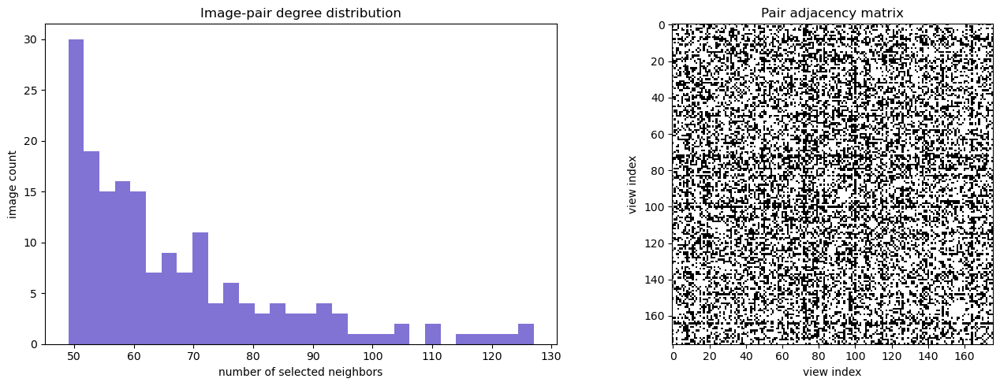

In [13]:
visualize_image_pairs(IMAGE_PAIRS)

## 7. FeatureMatching

`FeatureMatching` nhận danh sách pair từ bước trước, match descriptors, rồi lọc hình học bằng robust estimation. Đây là bước quyết định chất lượng graph ảnh trước khi SfM chạy.

Output cần kiểm tra:

- thư mục `matches` có file match được tạo;
- tổng dung lượng match không quá nhỏ;
- nếu log báo nhiều pair bị reject, cần xem lại overlap, blur hoặc tăng feature preset.

In [14]:
feature_matching_cmd = [
    av_tool("featureMatching"),
    "--input", CAMERA_INIT_SFM,
    "--featuresFolders", STAGE_DIRS["features"],
    "--imagePairsList", IMAGE_PAIRS,
    "--output", STAGE_DIRS["matches"],
    "--describerTypes", DESCRIBER_TYPES,
    "--geometricFilterType", "fundamental_matrix",
    "--geometricEstimator", "acransac",
    "--maxCoresAvailable", MAX_CORES,
    "--verboseLevel", "info",
]
run_command(feature_matching_cmd, "04_featureMatching")

$ /home/dacekey/dariusuav/alicevision/Meshroom-2023.3.0/aliceVision/bin/aliceVision_featureMatching --input /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/01_cameraInit/cameraInit.sfm --featuresFolders /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/02_features --imagePairsList /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/03_imageMatching/imagePairs.txt --output /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/04_matches --describerTypes sift --geometricFilterType fundamental_matrix --geometricEstimator acransac --maxCoresAvailable 12 --verboseLevel info
Log file: /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/reports/04_featureMatching.log
Exit code: 0 | elapsed: 21.3 min

Last log lines:
[14:44:19.917262][info] 	- image pair (1851844486, 2102330340) contains 383 geometric matches.
[14:44:19.917266][info] 	- image pair (1875178682, 1892583435) conta

PosixPath('/home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/reports/04_featureMatching.log')

/home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/04_matches: 1 files


,name,relative_path,suffix,size_mb
0,matches.txt,output/cache/04_matches/matches.txt,.txt,11.920342


,suffix,count,sum,mean
0,.txt,1,11.920342,11.920342


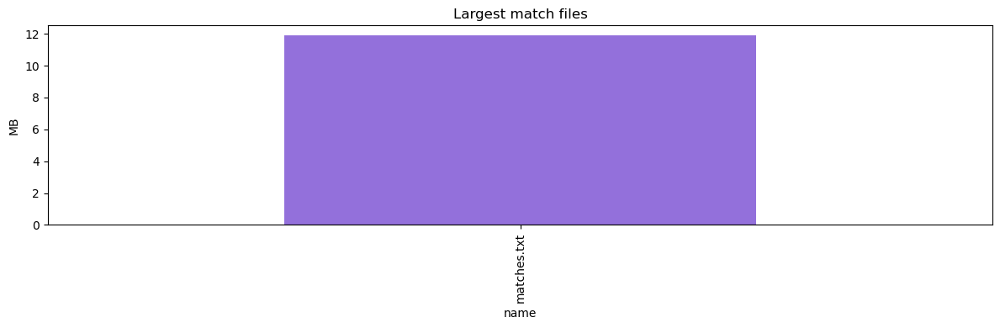

In [15]:
matches_df = show_file_inventory(STAGE_DIRS["matches"], patterns=("*",), recursive=True)
if not matches_df.empty:
    fig, ax = plt.subplots(figsize=(12, 4))
    matches_df.sort_values("size_mb", ascending=False).head(40).plot(
        x="name", y="size_mb", kind="bar", ax=ax, legend=False, color="mediumpurple"
    )
    ax.set_title("Largest match files")
    ax.set_ylabel("MB")
    ax.tick_params(axis="x", labelrotation=90)
    plt.tight_layout()
    plt.show()

## 8. IncrementalSfM

`IncrementalSfM` dựng camera poses và sparse point cloud. Bước này cho biết bộ ảnh có đủ overlap và match ổn định hay không.

Output cần kiểm tra:

- số `poses` càng gần số `views` càng tốt;
- sparse point cloud phải có hình dáng hợp lý;
- camera centers phải phân bố quanh đối tượng, không collapse thành một cụm bất thường.

In [16]:
sfm_cmd = [
    av_tool("incrementalSfM"),
    "--input", CAMERA_INIT_SFM,
    "--featuresFolders", STAGE_DIRS["features"],
    "--matchesFolders", STAGE_DIRS["matches"],
    "--output", SFM,
    "--outputViewsAndPoses", CAMERAS_SFM,
    "--extraInfoFolder", STAGE_DIRS["sfm"],
    "--describerTypes", DESCRIBER_TYPES,
    "--verboseLevel", "info",
]
run_command(sfm_cmd, "05_incrementalSfM")

$ /home/dacekey/dariusuav/alicevision/Meshroom-2023.3.0/aliceVision/bin/aliceVision_incrementalSfM --input /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/01_cameraInit/cameraInit.sfm --featuresFolders /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/02_features --matchesFolders /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/04_matches --output /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/05_sfm/sfm.sfm --outputViewsAndPoses /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/05_sfm/cameras.sfm --extraInfoFolder /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/05_sfm --describerTypes sift --verboseLevel info
Log file: /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/reports/05_incrementalSfM.log
Exit code: 0 | elapsed: 4.1 min

Last log lines:
83	|	0
84	|	1
85	|	0
86	|	1
87
[14:47:43.169736][info] Land

PosixPath('/home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/reports/05_incrementalSfM.log')

,views,intrinsics,poses,landmarks
0,176,1,173,166819


,viewId,poseId,intrinsicId,path,width,height
0,11855485,11855485,3674969038,MAX_0124.JPG,5472,3648
1,38932963,38932963,3674969038,MAX_0100.JPG,5472,3648
2,40390399,40390399,3674969038,MAX_0174.JPG,5472,3648
3,57733051,57733051,3674969038,MAX_0024.JPG,5472,3648
4,58599558,58599558,3674969038,MAX_0107.JPG,5472,3648
5,91331686,91331686,3674969038,MAX_0069.JPG,5472,3648
6,95700226,95700226,3674969038,MAX_0102.JPG,5472,3648
7,121530303,121530303,3674969038,MAX_0061.JPG,5472,3648
8,142491675,142491675,3674969038,MAX_0161.JPG,5472,3648
9,144974563,144974563,3674969038,MAX_0127.JPG,5472,3648


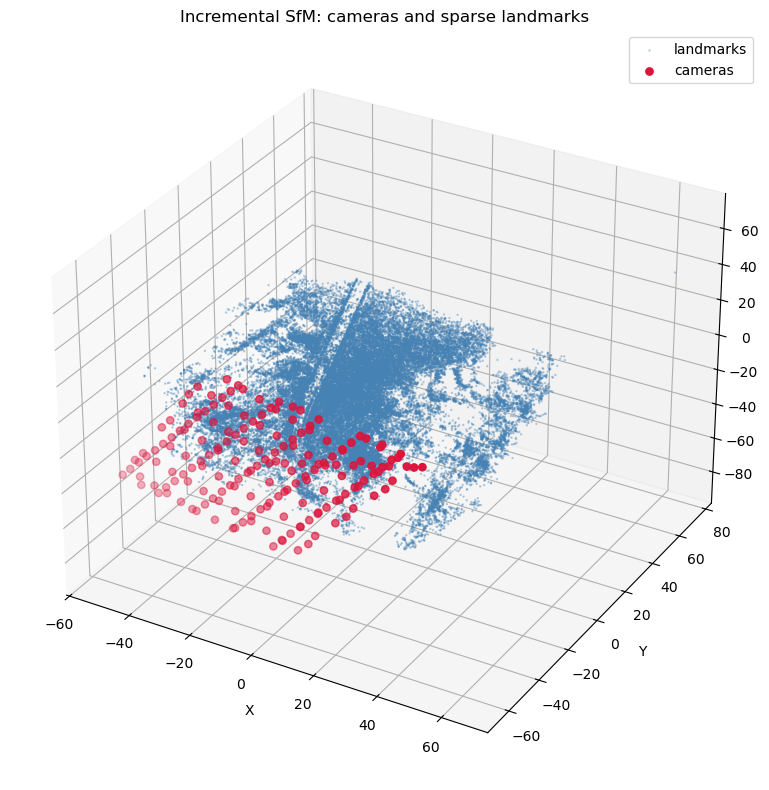

Registered camera ratio: 173/176 = 98.3%


In [17]:
sfm_result = summarize_sfm(SFM)
plot_sfm_3d(SFM, title="Incremental SfM: cameras and sparse landmarks")

views = len(sfm_result.get("views", []))
poses = len(sfm_result.get("poses", []))
if views:
    print(f"Registered camera ratio: {poses}/{views} = {poses / views:.1%}")

## 9. PrepareDenseScene

`PrepareDenseScene` tạo ảnh đã hiệu chỉnh/undistort theo kết quả SfM để phục vụ multi-view stereo. Notebook dùng `png` để dễ visualize trực tiếp; nếu muốn workflow sát Meshroom hơn và tiết kiệm precision màu, có thể đổi `PREPARE_DENSE_IMAGE_TYPE = "exr"` trước khi chạy.

Output cần kiểm tra:

- số ảnh prepared phải gần với số camera pose đã reconstruct;
- ảnh không bị xoay/crop sai nghiêm trọng;
- tên file thường theo view id, không nhất thiết giữ tên ảnh gốc.

In [18]:
prepare_dense_cmd = [
    av_tool("prepareDenseScene"),
    "--input", SFM,
    "--output", STAGE_DIRS["prepareDenseScene"],
    "--outputFileType", PREPARE_DENSE_IMAGE_TYPE,
    "--saveMatricesTxtFiles", 1,
    "--verboseLevel", "info",
]
run_command(prepare_dense_cmd, "06_prepareDenseScene")

$ /home/dacekey/dariusuav/alicevision/Meshroom-2023.3.0/aliceVision/bin/aliceVision_prepareDenseScene --input /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/05_sfm/sfm.sfm --output /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/06_prepareDenseScene --outputFileType png --saveMatricesTxtFiles 1 --verboseLevel info
Log file: /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/reports/06_prepareDenseScene.log
Exit code: 0 | elapsed: 9.2 min

Last log lines:
[2026-07-03 14:48:38.257277] [0x00007fd3804ae000] [trace]   Embedded OCIO configuration file: '/home/dacekey/dariusuav/alicevision/Meshroom-2023.3.0/aliceVision/share/aliceVision/config.ocio' found.
Program called with the following parameters:
 * evCorrection = 0 (default)
 * input = "/home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/05_sfm/sfm.sfm"
 * maskExtension = "png" (default)
 * maxCoresAvailable =  Unknown Type "j" (default)


PosixPath('/home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/reports/06_prepareDenseScene.log')

Prepared dense images: 173
/home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/06_prepareDenseScene: 519 files


,name,relative_path,suffix,size_mb
0,1004768684.png,output/cache/06_prepareDenseScene/1004768684.png,.png,34.600085
1,1004768684_KRt.txt,output/cache/06_prepareDenseScene/1004768684_K...,.txt,0.000209
2,1004768684_P.txt,output/cache/06_prepareDenseScene/1004768684_P...,.txt,0.000143
3,1039115835.png,output/cache/06_prepareDenseScene/1039115835.png,.png,40.872849
4,1039115835_KRt.txt,output/cache/06_prepareDenseScene/1039115835_K...,.txt,0.000206
5,1039115835_P.txt,output/cache/06_prepareDenseScene/1039115835_P...,.txt,0.000141
6,1053141325.png,output/cache/06_prepareDenseScene/1053141325.png,.png,42.553747
7,1053141325_KRt.txt,output/cache/06_prepareDenseScene/1053141325_K...,.txt,0.000210
8,1053141325_P.txt,output/cache/06_prepareDenseScene/1053141325_P...,.txt,0.000144
9,1054854377.png,output/cache/06_prepareDenseScene/1054854377.png,.png,38.304358


,suffix,count,sum,mean
0,.png,173,6787.984327,39.236904
1,.txt,346,0.060868,0.000176


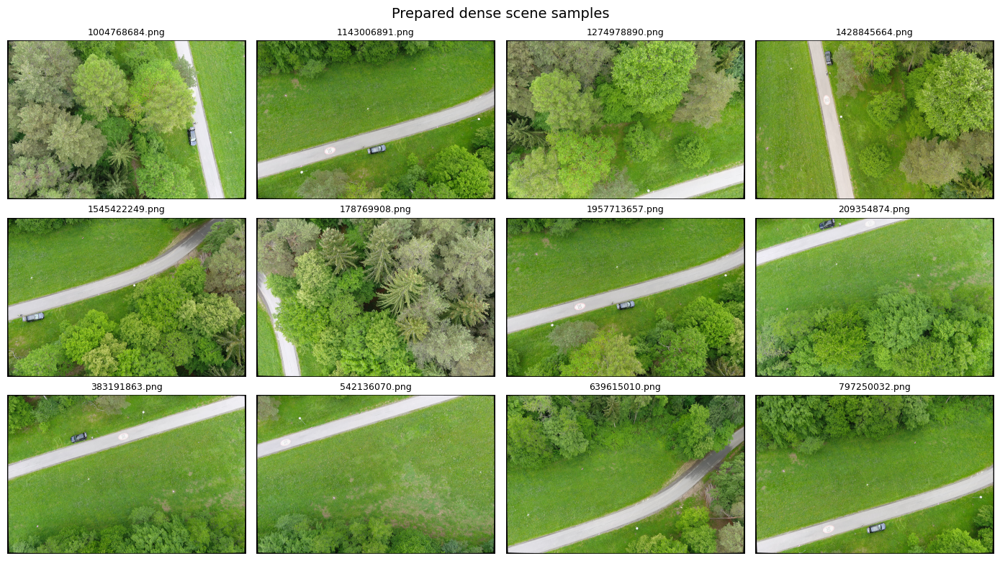

In [19]:
prepared_patterns = ("*.png", "*.jpg", "*.jpeg", "*.tif", "*.tiff", "*.exr")
prepared_files = list_files(STAGE_DIRS["prepareDenseScene"], patterns=prepared_patterns, recursive=False)
print(f"Prepared dense images: {len(prepared_files)}")
show_file_inventory(STAGE_DIRS["prepareDenseScene"], patterns=prepared_patterns + ("*.txt",), recursive=False)

viewable = [p for p in prepared_files if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".tif", ".tiff"}]
if viewable:
    display_image_grid(viewable[::max(1, len(viewable) // 12)], cols=4, title="Prepared dense scene samples")
else:
    visualize_scalar_maps(STAGE_DIRS["prepareDenseScene"], "Prepared dense scene samples")

## 10. DepthMapEstimation

`DepthMapEstimation` là bước dense reconstruction chính và yêu cầu NVIDIA CUDA GPU. Nếu bước này fail vì GPU/CUDA, cần kiểm tra driver và khả năng AliceVision nhìn thấy GPU.

Output cần kiểm tra:

- depth maps được tạo cho nhiều view;
- vùng depth hợp lệ không quá rỗng;
- depth maps không bị nhiễu lớn hoặc mất toàn bộ đối tượng.

In [20]:
depth_map_cmd = [
    av_tool("depthMapEstimation"),
    "--input", SFM,
    "--imagesFolder", STAGE_DIRS["prepareDenseScene"],
    "--output", STAGE_DIRS["depthMap"],
    "--downscale", DEPTH_DOWNSCALE,
    "--nbGPUs", 0,
    "--verboseLevel", "info",
]
run_command(depth_map_cmd, "07_depthMapEstimation")

$ /home/dacekey/dariusuav/alicevision/Meshroom-2023.3.0/aliceVision/bin/aliceVision_depthMapEstimation --input /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/05_sfm/sfm.sfm --imagesFolder /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/06_prepareDenseScene --output /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/07_depthMap --downscale 2 --nbGPUs 0 --verboseLevel info
Log file: /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/reports/07_depthMapEstimation.log
Exit code: 0 | elapsed: 67.8 min

Last log lines:
	      - id: 53
	      - view id: 700014106
	      - depth planes: 207
	      - depths range: [33.558-58.4178]
	      - depth indexes range: [0-207]
	   - T camera (2/4):
	      - id: 25
	      - view id: 383191863
	      - depth planes: 149
	      - depths range: [38.5577-58.4178]
	      - depth indexes range: [58-207]
	   - T camera (3/4):
	      - id: 141
	      - view id: 1

PosixPath('/home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/reports/07_depthMapEstimation.log')

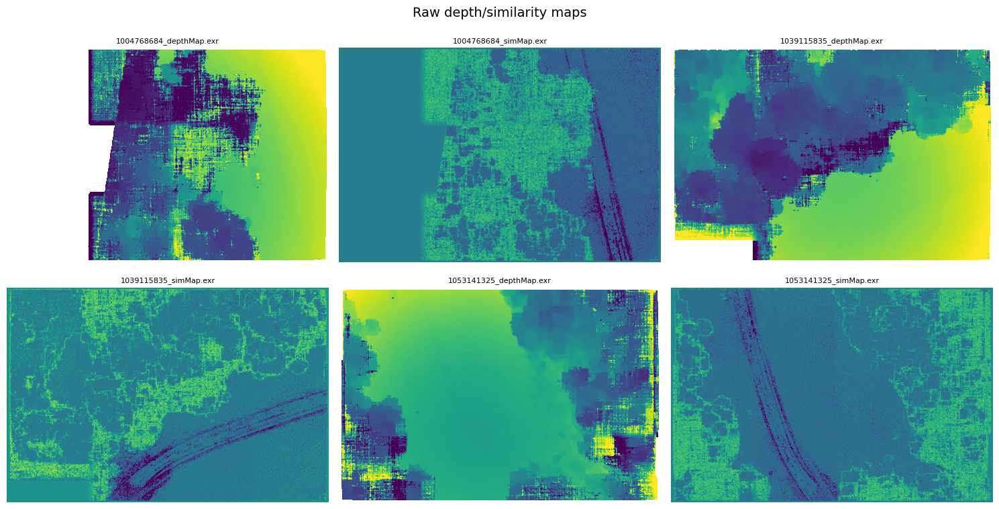

In [7]:
show_file_inventory(STAGE_DIRS["depthMap"], patterns=("*.exr", "*.png", "*.tif", "*.txt"), recursive=True)
visualize_scalar_maps(STAGE_DIRS["depthMap"], "Raw depth/similarity maps")

## 11. DepthMapFiltering

`DepthMapFiltering` loại các depth values không nhất quán giữa nhiều camera. Kết quả sau lọc thường sạch hơn và phù hợp để fusion thành mesh.

Output cần kiểm tra:

- số filtered maps tương ứng với raw depth maps;
- vùng depth còn giữ được object chính;
- nếu filtered maps quá rỗng, có thể do match/SfM yếu hoặc tham số consistency quá chặt.

In [22]:
depth_filter_cmd = [
    av_tool("depthMapFiltering"),
    "--input", SFM,
    "--depthMapsFolder", STAGE_DIRS["depthMap"],
    "--output", STAGE_DIRS["depthMapFilter"],
    "--computeNormalMaps", 1,
    "--verboseLevel", "info",
]
run_command(depth_filter_cmd, "08_depthMapFiltering")

$ /home/dacekey/dariusuav/alicevision/Meshroom-2023.3.0/aliceVision/bin/aliceVision_depthMapFiltering --input /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/05_sfm/sfm.sfm --depthMapsFolder /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/07_depthMap --output /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/08_depthMapFilter --computeNormalMaps 1 --verboseLevel info
Log file: /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/reports/08_depthMapFiltering.log
Exit code: 0 | elapsed: 10.0 min

Last log lines:
[16:15:28.136984][info] Compute normal map (rc: 153) done in: 481 ms.
[16:15:28.137505][info] Compute normal map (rc: 154)
[16:15:29.360676][info] Compute normal map (rc: 154) done in: 1223 ms.
[16:15:29.361161][info] Compute normal map (rc: 155)
[16:15:29.832565][info] Compute normal map (rc: 155) done in: 471 ms.
[16:15:29.833001][info] Compute normal map (rc: 156)
[16:15:31.85956

PosixPath('/home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/reports/08_depthMapFiltering.log')

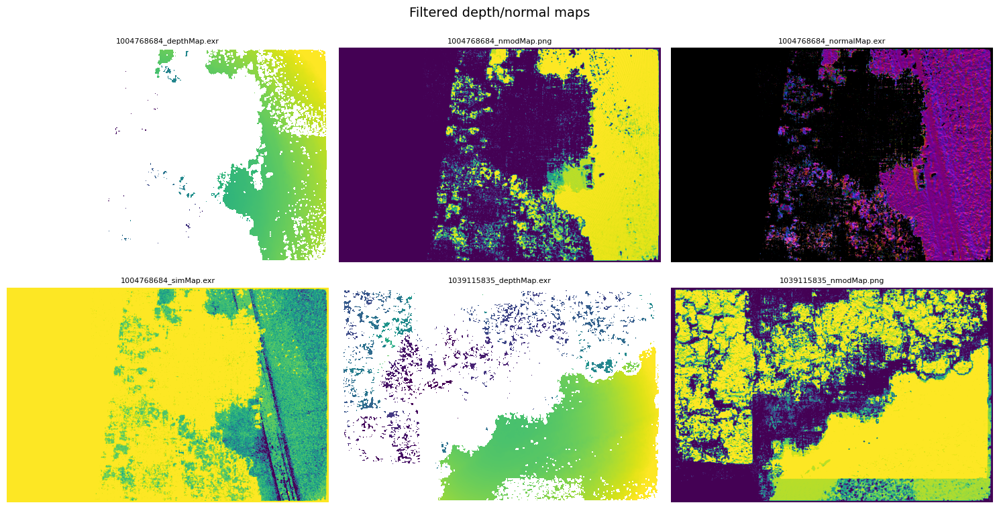

In [8]:
show_file_inventory(STAGE_DIRS["depthMapFilter"], patterns=("*.exr", "*.png", "*.tif", "*.txt"), recursive=True)
visualize_scalar_maps(STAGE_DIRS["depthMapFilter"], "Filtered depth/normal maps")

## 12. Meshing

`Meshing` fuse filtered depth maps thành dense point cloud và mesh thô. Notebook lưu dense SfMData ở dạng `.abc` vì đây là format Meshroom/AliceVision thường dùng cho texturing, đồng thời xuất mesh thô `.obj` để dễ thống kê và visualize.

Output cần kiểm tra:

- `mesh.obj` tồn tại và có số vertices/faces hợp lý;
- bounding box không bị cực đoan;
- hình mesh preview có dạng gần đúng của đối tượng/cảnh.

In [4]:
meshing_cmd = [
    av_tool("meshing"),
    "--input", SFM,
    "--depthMapsFolder", STAGE_DIRS["depthMapFilter"],
    "--output", DENSE_SFM,
    "--outputMesh", RAW_MESH,
    "--colorizeOutput", 1,
    "--verboseLevel", "info",
    "--maxInputPoints", 10000000,  # 10 triệu điểm đầu vào
    "--maxPoints", 1500000,        # 1.5 triệu điểm đỉnh 3D
    "--maxCoresAvailable", 10,     # Dùng 10/12 luồng CPU
]
run_command(meshing_cmd, "09_meshing")

$ /home/dacekey/dariusuav/alicevision/Meshroom-2023.3.0/aliceVision/bin/aliceVision_meshing --input /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/05_sfm/sfm.sfm --depthMapsFolder /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/08_depthMapFilter --output /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/09_meshing/densePointCloud.abc --outputMesh /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/09_meshing/mesh.obj --colorizeOutput 1 --verboseLevel info --maxInputPoints 10000000 --maxPoints 1500000 --maxCoresAvailable 10
Log file: /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/reports/09_meshing.log
Exit code: 0 | elapsed: 9.3 min

Last log lines:
[20:32:36.641855][info] computeIsOnSurface nbSurfaceFacets: 1934224
[20:32:37.119575][warning] [0] Check solid angle full/empty ratio on surface vertices: 278318 cells moved to full, 324200 cells moved to empty w

PosixPath('/home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/reports/09_meshing.log')

,path,exists,vertices,faces,size_mb,bbox_x,bbox_y,bbox_z
0,/home/dacekey/dariusuav/alicevision/project/P0...,True,803437,1639830,68.901178,111.421543,32.422554,143.725525


Interactive mesh preview unavailable, falling back to vertex scatter. Reason: No module named 'trimesh'


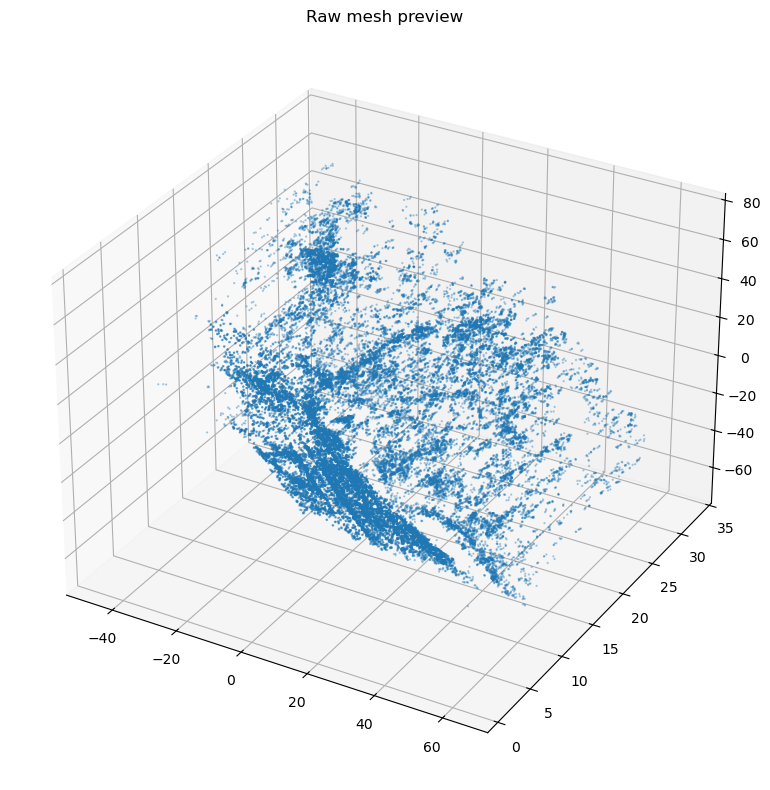

/home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/09_meshing: 2 files


,name,relative_path,suffix,size_mb
0,densePointCloud.abc,output/cache/09_meshing/densePointCloud.abc,.abc,138.561981
1,mesh.obj,output/cache/09_meshing/mesh.obj,.obj,68.901178


,suffix,count,sum,mean
0,.abc,1,138.561981,138.561981
1,.obj,1,68.901178,68.901178


,name,relative_path,suffix,size_mb
0,densePointCloud.abc,output/cache/09_meshing/densePointCloud.abc,.abc,138.561981
1,mesh.obj,output/cache/09_meshing/mesh.obj,.obj,68.901178


In [5]:
raw_mesh_stats = obj_stats(RAW_MESH)
display(pd.DataFrame([raw_mesh_stats]))
preview_obj(RAW_MESH, title="Raw mesh preview")
show_file_inventory(STAGE_DIRS["meshing"], patterns=("*.obj", "*.mtl", "*.abc", "*.ply"), recursive=False)

## 13. MeshFiltering

`MeshFiltering` loại tam giác lỗi, làm mượt và có thể giữ connected component lớn nhất. Đây là bước làm sạch trước texturing.

Output cần kiểm tra:

- số faces/vertices giảm vừa phải, không mất toàn bộ mesh;
- preview sau lọc vẫn giữ hình dạng chính;
- nếu mất nhiều chi tiết, giảm smoothing/filtering hoặc không bật `keepLargestMeshOnly`.

In [6]:
mesh_filter_cmd = [
    av_tool("meshFiltering"),
    "--inputMesh", RAW_MESH,
    "--outputMesh", FILTERED_MESH,
    "--keepLargestMeshOnly", 1,
    "--smoothingIterations", 5,
    "--filteringIterations", 1,
    "--verboseLevel", "info",
]
run_command(mesh_filter_cmd, "10_meshFiltering")

$ /home/dacekey/dariusuav/alicevision/Meshroom-2023.3.0/aliceVision/bin/aliceVision_meshFiltering --inputMesh /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/09_meshing/mesh.obj --outputMesh /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/10_meshFiltering/mesh_filtered.obj --keepLargestMeshOnly 1 --smoothingIterations 5 --filteringIterations 1 --verboseLevel info
Log file: /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/reports/10_meshFiltering.log
Exit code: 0 | elapsed: 0.3 min

Last log lines:
	OpenMP will use 12 cores
	Detected available memory : 9083 Mo

[20:33:57.317949][info] Mesh file: "/home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/09_meshing/mesh.obj" loaded.
[20:33:57.318043][info] Input mesh: 803437 vertices and 1639830 facets.
[20:33:57.318051][info] Start mesh filtering.
[20:33:57.318053][info] Mesh filtering: iteration 0
[20:33:57.318209][info] Filtering large trian

PosixPath('/home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/reports/10_meshFiltering.log')

,stage,exists,vertices,faces,size_mb,bbox_x,bbox_y,bbox_z
0,raw,True,803437,1639830,68.901178,111.421543,32.422554,143.725525
1,filtered,True,803810,1607753,68.098950,111.248154,32.250663,143.374985


Interactive mesh preview unavailable, falling back to vertex scatter. Reason: No module named 'trimesh'


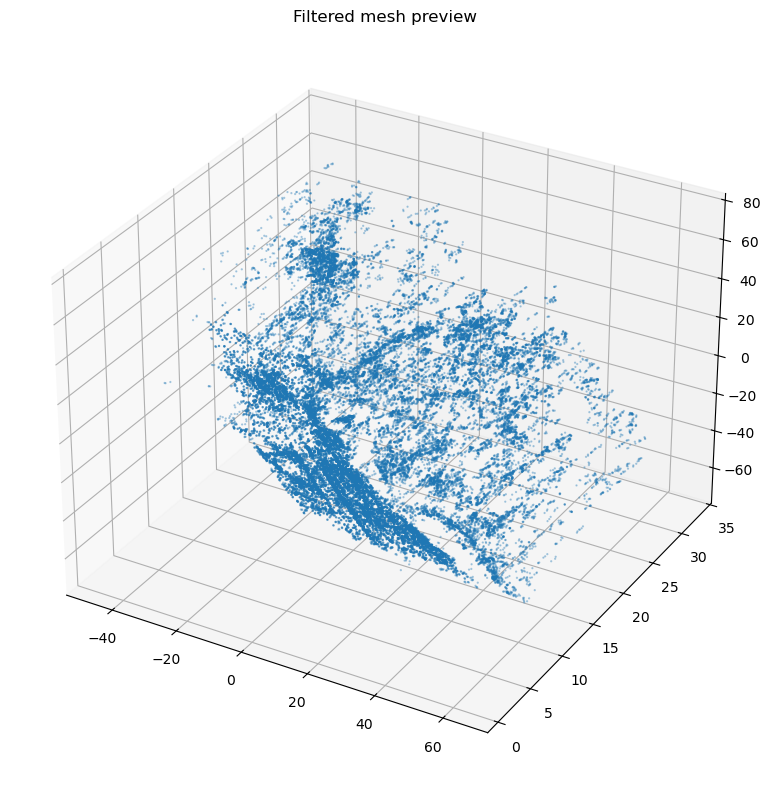

In [7]:
mesh_compare = pd.DataFrame([obj_stats(RAW_MESH), obj_stats(FILTERED_MESH)])
mesh_compare["stage"] = ["raw", "filtered"]
display(mesh_compare[["stage", "exists", "vertices", "faces", "size_mb", "bbox_x", "bbox_y", "bbox_z"]])
preview_obj(FILTERED_MESH, title="Filtered mesh preview")

## 14. Texturing

`Texturing` chiếu màu từ ảnh prepared lên mesh đã lọc và xuất textured mesh cuối cùng. Output thường gồm `.obj`, `.mtl`, và một hoặc nhiều texture atlas image.

Output cần kiểm tra:

- textured mesh load được;
- texture atlas có nội dung rõ, không đen/rỗng;
- seams và vùng thiếu texture có chấp nhận được không.

In [8]:
texturing_cmd = [
    av_tool("texturing"),
    "--input", DENSE_SFM,
    "--inputMesh", FILTERED_MESH,
    "--imagesFolder", STAGE_DIRS["prepareDenseScene"],
    "--output", TEXTURED_DIR,
    "--textureSide", TEXTURE_SIDE,
    "--outputMeshFileType", "obj",
    "--fillHoles", 1,
    "--verboseLevel", "info",
]
run_command(texturing_cmd, "11_texturing")

$ /home/dacekey/dariusuav/alicevision/Meshroom-2023.3.0/aliceVision/bin/aliceVision_texturing --input /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/09_meshing/densePointCloud.abc --inputMesh /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/10_meshFiltering/mesh_filtered.obj --imagesFolder /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/cache/06_prepareDenseScene --output /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/texturing --textureSide 8192 --outputMeshFileType obj --fillHoles 1 --verboseLevel info
Log file: /home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/reports/11_texturing.log
Exit code: 0 | elapsed: 0.7 min

Last log lines:
[20:34:27.268041][info] remapMeshVisibility based on triangles start.
[20:34:31.578906][info] remapMeshVisibility done.
[20:34:31.579646][info] Input mesh has no UV coordinates, start unwrapping (Basic)
[20:34:31.579764][info] Generati

PosixPath('/home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/reports/11_texturing.log')

/home/dacekey/dariusuav/alicevision/project/P01_first-practice/output/texturing: 2 files


,name,relative_path,suffix,size_mb
0,texturedMesh.mtl,output/texturing/texturedMesh.mtl,.mtl,0.001091
1,texturedMesh.obj,output/texturing/texturedMesh.obj,.obj,124.607485


,suffix,count,sum,mean
0,.mtl,1,0.001091,0.001091
1,.obj,1,124.607485,124.607485


,path,exists,vertices,faces,size_mb,bbox_x,bbox_y,bbox_z
0,/home/dacekey/dariusuav/alicevision/project/P0...,True,803810,1607753,124.607485,111.248154,32.250663,143.374985


Interactive mesh preview unavailable, falling back to vertex scatter. Reason: No module named 'trimesh'


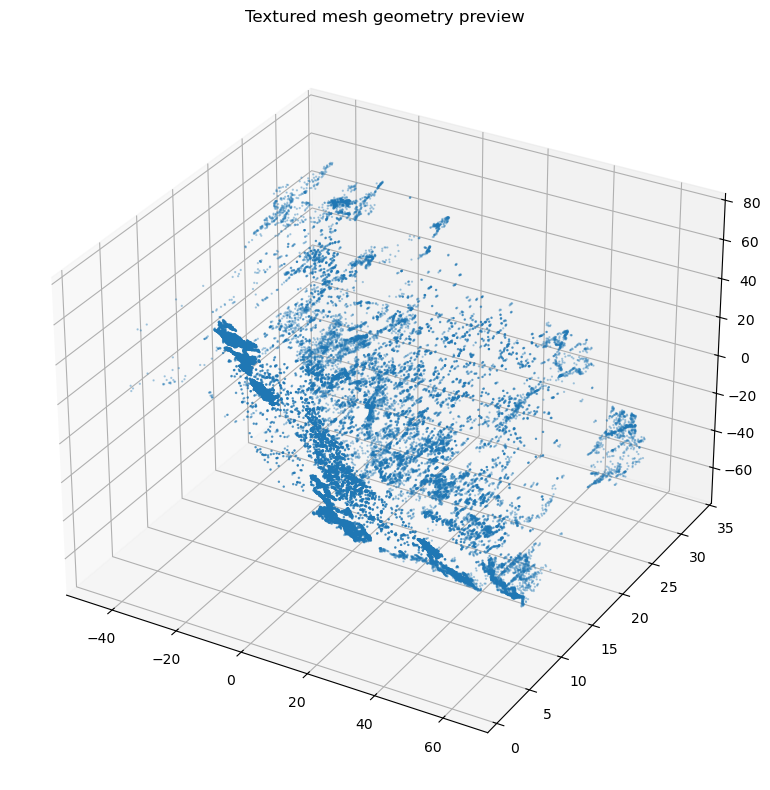

In [9]:
texturing_df = show_file_inventory(TEXTURED_DIR, patterns=("*.obj", "*.mtl", "*.png", "*.jpg", "*.jpeg", "*.tif", "*.tiff"), recursive=True)

texture_images = list_files(TEXTURED_DIR, patterns=("*.png", "*.jpg", "*.jpeg", "*.tif", "*.tiff"), recursive=True)
if texture_images:
    display_image_grid(texture_images, cols=3, figsize=(14, 8), title="Texture atlas outputs", max_images=6)

textured_objs = list_files(TEXTURED_DIR, patterns=("*.obj",), recursive=True)
if textured_objs:
    textured_mesh = textured_objs[0]
    display(pd.DataFrame([obj_stats(textured_mesh)]))
    preview_obj(textured_mesh, title="Textured mesh geometry preview")
else:
    print("No textured OBJ found yet.")

## 15. Tổng hợp trạng thái output

Cell cuối tạo bảng checkpoint để biết stage nào đã hoàn tất và output chính đang nằm ở đâu.

In [10]:
checkpoints = [
    ("CameraInit SfM", CAMERA_INIT_SFM),
    ("Image pairs", IMAGE_PAIRS),
    ("SfM result", SFM),
    ("Dense SfMData", DENSE_SFM),
    ("Raw mesh", RAW_MESH),
    ("Filtered mesh", FILTERED_MESH),
]

rows = []
for label, path in checkpoints:
    rows.append({
        "checkpoint": label,
        "exists": path.exists(),
        "path": str(path),
        "size_mb": file_size_mb(path) if path.exists() else None,
    })

folder_rows = []
for label, folder in STAGE_DIRS.items():
    files = list_files(folder, patterns=("*",), recursive=True) if folder.exists() else []
    folder_rows.append({
        "stage": label,
        "folder_exists": folder.exists(),
        "file_count": len(files),
        "total_mb": sum(file_size_mb(p) for p in files) if files else 0,
        "folder": str(folder),
    })

display(pd.DataFrame(rows))
display(pd.DataFrame(folder_rows))

,checkpoint,exists,path,size_mb
0,CameraInit SfM,True,/home/dacekey/dariusuav/alicevision/project/P0...,0.757622
1,Image pairs,True,/home/dacekey/dariusuav/alicevision/project/P0...,0.061254
2,SfM result,True,/home/dacekey/dariusuav/alicevision/project/P0...,218.432193
3,Dense SfMData,True,/home/dacekey/dariusuav/alicevision/project/P0...,138.561981
4,Raw mesh,True,/home/dacekey/dariusuav/alicevision/project/P0...,68.901178
5,Filtered mesh,True,/home/dacekey/dariusuav/alicevision/project/P0...,68.098950


,stage,folder_exists,file_count,total_mb,folder
0,cameraInit,True,1,0.757622,/home/dacekey/dariusuav/alicevision/project/P0...
1,features,True,352,673.614547,/home/dacekey/dariusuav/alicevision/project/P0...
2,imageMatching,True,1,0.061254,/home/dacekey/dariusuav/alicevision/project/P0...
3,matches,True,1,11.920342,/home/dacekey/dariusuav/alicevision/project/P0...
4,sfm,True,8,225.410471,/home/dacekey/dariusuav/alicevision/project/P0...
5,prepareDenseScene,True,519,6788.045196,/home/dacekey/dariusuav/alicevision/project/P0...
6,depthMap,True,346,4315.233024,/home/dacekey/dariusuav/alicevision/project/P0...
7,depthMapFilter,True,692,6100.084487,/home/dacekey/dariusuav/alicevision/project/P0...
8,meshing,True,3,207.463243,/home/dacekey/dariusuav/alicevision/project/P0...
9,meshFiltering,True,1,68.098950,/home/dacekey/dariusuav/alicevision/project/P0...
